Yoon: using frame t = 0.500000
CentPack: using output n = 10 (t = 3.141593, want 3.141593)

field |                   Yoon |               CentPack |   CentPack vs Yoon
      |     rel L2        corr |     rel L2        corr |
  rho |     0.925%    0.999534 |     2.072%    0.997710 |   2.152%   0.997533
    p |     1.496%    0.999482 |     2.995%    0.997942 |   3.166%   0.997695
    u |     2.286%    0.999739 |     4.608%    0.998938 |   4.582%   0.998950
    v |     2.236%    0.999750 |     4.108%    0.999163 |   4.105%   0.999163
   Bx |     2.413%    0.999709 |     4.341%    0.999072 |   5.048%   0.998736
   By |     2.123%    0.999775 |     2.787%    0.999612 |   3.584%   0.999358

saved /Users/evandaniels/Research/runs/ot/ot_256_di1em8/ot_comparison.png


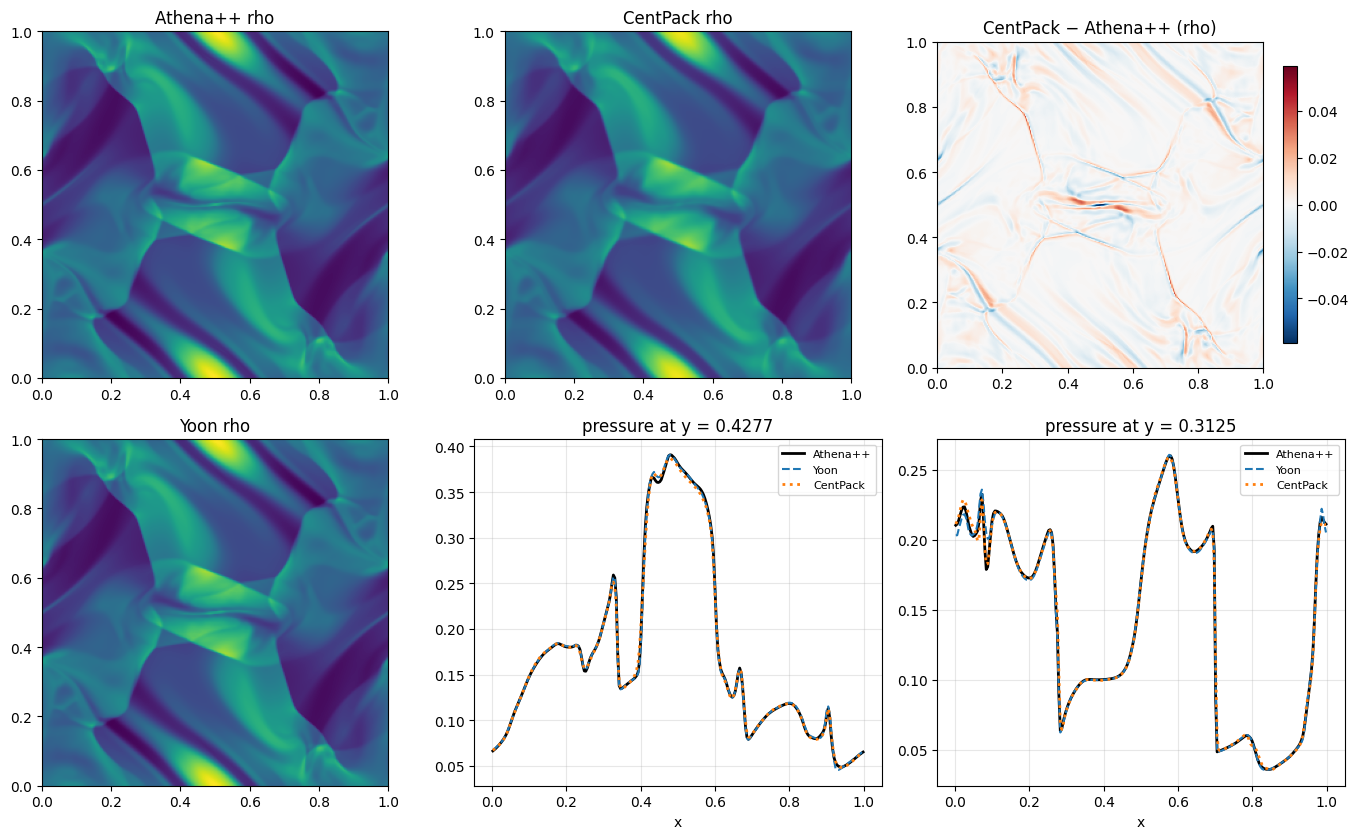

In [8]:
"""
compare_ot_three.py -- Orszag-Tang at t = 0.5: CentPack vs Yoon's HallMHDcode vs Athena++

Reference: Athena++ 256x256 (HLLD, VL2, PLM, CT), shipped in Yoon's repo as
reference/orszag_tang_athena_256.npz. Arrays there are indexed [y, x] on [0,1]^2.

Normalization (Athena/Yoon):  rho = 25/(36 pi), p = 5/(12 pi),
  v = (-sin 2pi y, sin 2pi x),  B = (-sin 2pi y, sin 4pi x)/sqrt(4 pi),  gamma = 5/3

If your CentPack OT uses the other common form on [0, 2pi]
(rho = gamma^2, p = gamma, v = (-sin y, sin x), B = (-sin y, sin 2x)),
set CP_FORM = 'jw'. That form is the same flow with
  x -> x/(2pi),  t -> t/(2pi),  rho,p -> /(4pi),  B -> /sqrt(4pi),  v unchanged,
so compare CentPack at t = pi against Athena at t = 0.5.

Metrics follow Yoon's compare_orszag_tang.py: relative L2 and correlation,
plus pressure cuts at y = 0.4277 and 0.3125.
"""
import os
import numpy as np
import matplotlib.pyplot as plt

# ---------------------------------------------------------------- settings
ATHENA = os.path.expanduser('~/Research/yoon/HallMHDcode/reference/orszag_tang_athena_256.npz')
YOON   = os.path.expanduser('~/Research/yoon/HallMHDcode/output/orszag_tang.h5')  # None to skip
# CP_RUN = os.path.expanduser('~/Research/runs/ot/ot_256')
CP_RUN = os.path.expanduser('~/Research/runs/ot/ot_256_di1em8')
CP_P      = 8        # MPI ranks used for the CentPack run
CP_DT_OUT = 0.314159265358979
CP_FORM   = 'jw'
T_REF     = 0.5      # Athena time
SLICES    = (0.4277, 0.3125)

FIELDS = ['rho', 'p', 'u', 'v', 'Bx', 'By']
CP_NAMES = {'rho': 'rho', 'p': 'p', 'u': 'u1', 'v': 'u2', 'Bx': 'b1', 'By': 'b2'}


# ---------------------------------------------------------------- loaders
def load_athena():
    d = np.load(ATHENA, allow_pickle=False)
    return d['x'], d['y'], {f: np.array(d[f]) for f in FIELDS}


def load_yoon():
    import h5py
    with h5py.File(YOON, 'r') as h:
        t = h['time'][:]
        n = int(np.argmin(np.abs(t - T_REF)))
        print(f'Yoon: using frame t = {t[n]:.6f}')
        return h['x'][:], h['y'][:], {f: h[f'fields/{f}'][n] for f in FIELDS}


def load_centpack():
    if CP_FORM == 'jw':
        Lscale, t_cp = 1/(2*np.pi), T_REF*2*np.pi
        fscale = {'rho': 1/(4*np.pi), 'p': 1/(4*np.pi), 'u': 1.0, 'v': 1.0,
                  'Bx': 1/np.sqrt(4*np.pi), 'By': 1/np.sqrt(4*np.pi)}
    else:
        Lscale, t_cp = 1.0, T_REF
        fscale = {f: 1.0 for f in FIELDS}
    n = int(round(t_cp / CP_DT_OUT))
    print(f'CentPack: using output n = {n} (t = {n*CP_DT_OUT:.6f}, want {t_cp:.6f})')
    if abs(n*CP_DT_OUT - t_cp) > 1e-6:
        raise SystemExit('No CentPack output at the comparison time. For CP_FORM="jw" set '
                         't_final = 3.14159265358979 and dt_out = t_final/10 (and CP_DT_OUT to match).')

    x = np.concatenate([np.loadtxt(f'{CP_RUN}/mesh_files/x_p{p:03d}') for p in range(CP_P)])
    y = np.loadtxt(f'{CP_RUN}/mesh_files/y')

    def ld(name):
        a = np.vstack([np.loadtxt(f'{CP_RUN}/{name}_files/{name}_p{p:03d}_{n:03d}')
                       for p in range(CP_P)])
        return a.T                       # CentPack is [x, y]; reference is [y, x]

    # map coordinates onto [0,1) and reorder so they line up with the reference grid
    xs, ys = (x*Lscale) % 1.0, (y*Lscale) % 1.0
    ix, iy = np.argsort(xs), np.argsort(ys)
    out = {f: (ld(CP_NAMES[f])*fscale[f])[np.ix_(iy, ix)] for f in FIELDS}
    return xs[ix], ys[iy], out


# ---------------------------------------------------------------- metrics
def metrics(a, ref):
    d = a - ref
    return np.sqrt(np.mean(d**2)) / np.sqrt(np.mean(ref**2)), np.corrcoef(a.ravel(), ref.ravel())[0, 1]


def ycut(field, y, loc):
    dy = np.median(np.diff(y)); pos = (loc - y[0]) / dy
    lo = int(np.floor(pos)); w = pos - lo
    return (1-w)*field[lo % len(y)] + w*field[(lo+1) % len(y)]


xa, ya, A = load_athena()
codes = {}
if YOON and os.path.isfile(YOON):
    xy, yy, Y = load_yoon(); codes['Yoon'] = (xy, yy, Y)
else:
    print('Yoon output not found, skipping')
xc, yc, C = load_centpack(); codes['CentPack'] = (xc, yc, C)

for name, (x, y, F) in codes.items():
    if not (np.allclose(x, xa, atol=1e-6) and np.allclose(y, ya, atol=1e-6)):
        print(f'WARNING: {name} grid does not match the Athena grid '
              f'(dx={np.diff(x).mean():.5f} vs {np.diff(xa).mean():.5f}); '
              f'check resolution, domain and CP_FORM')

print(f"\n{'field':>5s} | " + ' | '.join(f'{n:>22s}' for n in codes) + ' |   CentPack vs Yoon')
print(f"{'':>5s} | " + ' | '.join(f"{'rel L2':>10s} {'corr':>11s}" for _ in codes) + ' |')
for f in FIELDS:
    row = []
    for name, (_, _, F) in codes.items():
        l2, r = metrics(F[f], A[f]); row.append(f'{l2:10.3%} {r:11.6f}')
    cross = ''
    if 'Yoon' in codes:
        l2, r = metrics(codes['CentPack'][2][f], codes['Yoon'][2][f]); cross = f'{l2:8.3%} {r:10.6f}'
    print(f'{f:>5s} | ' + ' | '.join(row) + ' | ' + cross)

# ---------------------------------------------------------------- figure
fig, ax = plt.subplots(2, 3, figsize=(14, 8.5))
ext = [0, 1, 0, 1]
vmin, vmax = A['rho'].min(), A['rho'].max()
ax[0, 0].imshow(A['rho'], origin='lower', extent=ext, vmin=vmin, vmax=vmax); ax[0, 0].set_title('Athena++ rho')
ax[0, 1].imshow(C['rho'], origin='lower', extent=ext, vmin=vmin, vmax=vmax); ax[0, 1].set_title('CentPack rho')
lim = np.abs(C['rho'] - A['rho']).max()
im = ax[0, 2].imshow(C['rho'] - A['rho'], origin='lower', extent=ext, cmap='RdBu_r', vmin=-lim, vmax=lim)
ax[0, 2].set_title('CentPack − Athena++ (rho)'); fig.colorbar(im, ax=ax[0, 2], shrink=0.8)
if 'Yoon' in codes:
    Y = codes['Yoon'][2]
    ax[1, 0].imshow(Y['rho'], origin='lower', extent=ext, vmin=vmin, vmax=vmax); ax[1, 0].set_title('Yoon rho')
else:
    ax[1, 0].axis('off')
for k, loc in enumerate(SLICES):
    a = ax[1, 1 + k]
    a.plot(xa, ycut(A['p'], ya, loc), 'k-', lw=2, label='Athena++')
    if 'Yoon' in codes:
        a.plot(xa, ycut(codes['Yoon'][2]['p'], ya, loc), '--', label='Yoon')
    a.plot(xa, ycut(C['p'], ya, loc), ':', lw=2, label='CentPack')
    a.set_title(f'pressure at y = {loc}'); a.set_xlabel('x'); a.legend(fontsize=8); a.grid(alpha=0.3)
fig.tight_layout()
out = os.path.join(CP_RUN, 'ot_comparison.png')
fig.savefig(out, dpi=150); print(f'\nsaved {out}')
plt.show()

In [7]:
import os, numpy as np
runs = {}
for tag in ('ot_256', 'ot_256_di1em8'):
    CP_RUN = os.path.expanduser(f'~/Research/runs/ot/{tag}')
    runs[tag] = load_centpack()[2]

print(f"{'field':>5s} {'max |diff|':>12s} {'max |field|':>12s} {'relative':>10s}")
for f in FIELDS:
    a, b = runs['ot_256'][f], runs['ot_256_di1em8'][f]
    d = np.abs(a - b).max(); s = np.abs(a).max()
    print(f'{f:>5s} {d:12.3e} {s:12.3e} {d/s:10.2e}')

CentPack: using output n = 10 (t = 3.141593, want 3.141593)
CentPack: using output n = 10 (t = 3.141593, want 3.141593)
field   max |diff|  max |field|   relative
  rho    2.973e-08    4.860e-01   6.12e-08
    p    3.116e-08    5.086e-01   6.13e-08
    u    8.722e-08    1.328e+00   6.57e-08
    v    1.192e-07    1.064e+00   1.12e-07
   Bx    7.138e-08    6.530e-01   1.09e-07
   By    1.383e-08    6.488e-01   2.13e-08
